downloading the dataset

In [34]:
import os
from scipy.io import wavfile as wav

DATASET_PATH = r"C:\Users\Admin\Desktop\DATA SCIENCE\semester 4\Digital signal and image management\recordings"

files = sorted(os.listdir(DATASET_PATH))

print("Number of files:", len(files))
print("First 10 files:", files[:10])

Number of files: 1500
First 10 files: ['0_jackson_0.wav', '0_jackson_1.wav', '0_jackson_10.wav', '0_jackson_11.wav', '0_jackson_12.wav', '0_jackson_13.wav', '0_jackson_14.wav', '0_jackson_15.wav', '0_jackson_16.wav', '0_jackson_17.wav']


Import libraries

In [35]:
import os
import numpy as np
from time import time
from scipy.io import wavfile as wav
from scipy.signal import spectrogram

import matplotlib.pyplot as plt
import librosa

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
from scipy.fft import rfft, rfftfreq

import warnings
warnings.filterwarnings("ignore")

try:
    from librosa.feature import melspectrogram, mfcc
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "librosa"])
    from librosa.feature import melspectrogram, mfcc

Load one sample audio file

In [36]:
sample_file = files[0]

rate, signal = wav.read(os.path.join(DATASET_PATH, sample_file))
signal = signal.astype(float)

print("Sample file:", sample_file)
print("Sampling rate:", rate)
print("Signal shape:", signal.shape)

Sample file: 0_jackson_0.wav
Sampling rate: 8000
Signal shape: (5148,)


plot wave form

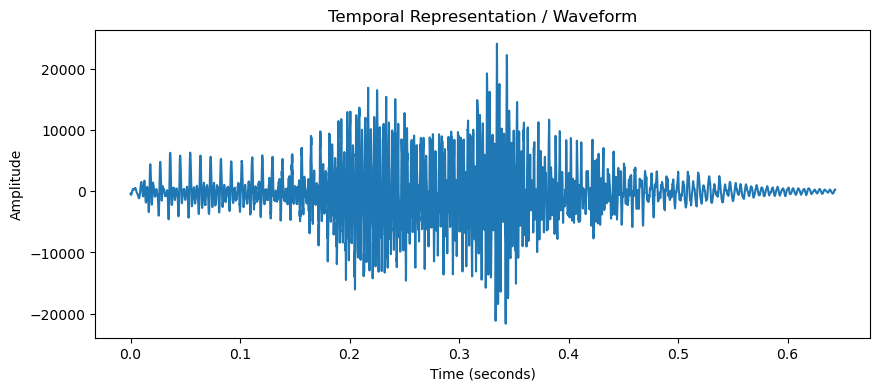

In [37]:
time_axis = np.arange(len(signal)) / rate

plt.figure(figsize=(10, 4))
plt.plot(time_axis, signal)
plt.title("Temporal Representation / Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

plot frequency representation

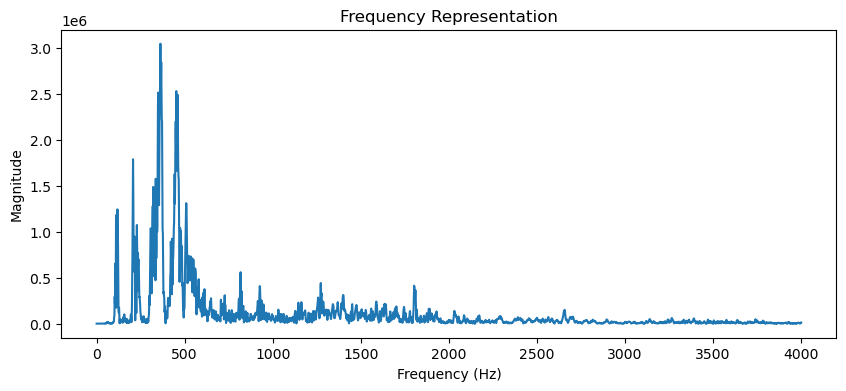

In [38]:
fft_values = np.abs(rfft(signal))
freqs = rfftfreq(len(signal), 1 / rate)

plt.figure(figsize=(10, 4))
plt.plot(freqs, fft_values)
plt.title("Frequency Representation")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.show()

plot spectrogram

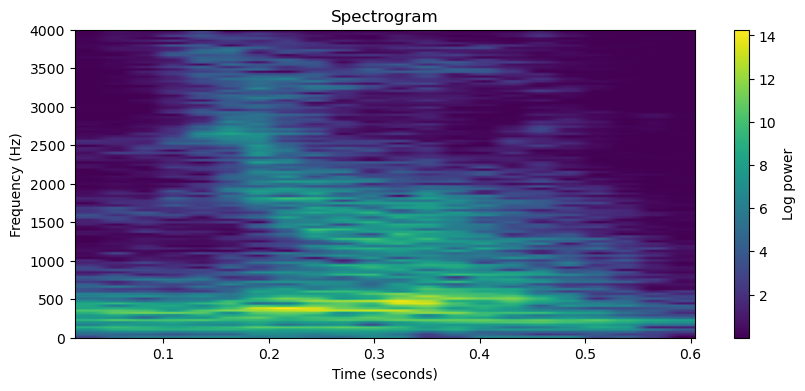

In [39]:
spec_freqs, spec_times, spec = spectrogram(signal, fs=rate)

plt.figure(figsize=(10, 4))
plt.imshow(
    np.log1p(spec),
    extent=[spec_times[0], spec_times[-1], spec_freqs[0], spec_freqs[-1]],
    origin="lower",
    aspect="auto"
)
plt.title("Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Log power")
plt.show()

plot mel spectrogram

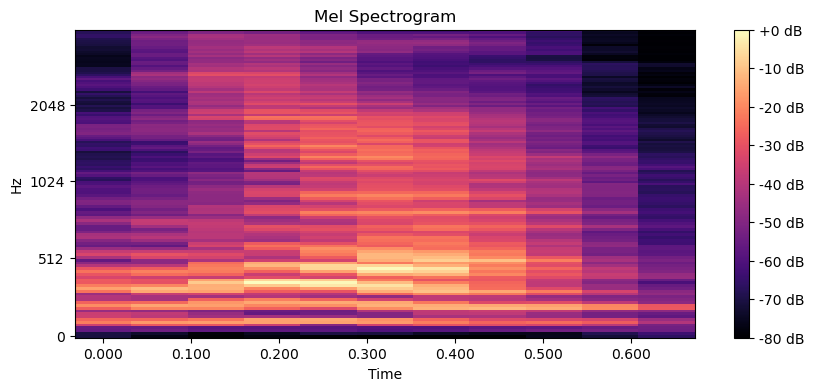

In [40]:
mel_spec = librosa.feature.melspectrogram(
    y=signal,
    sr=rate,
    n_mels=128
)

mel_db = librosa.power_to_db(mel_spec, ref=np.max)

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    mel_db,
    sr=rate,
    x_axis="time",
    y_axis="mel"
)
plt.title("Mel Spectrogram")
plt.colorbar(format="%+2.0f dB")
plt.show()

plot MFCC

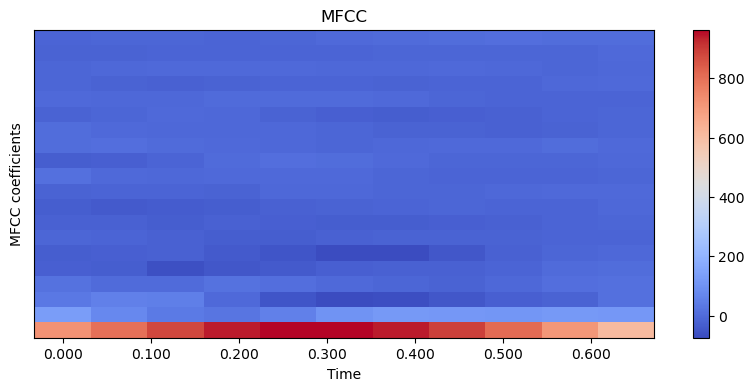

In [41]:
mfccs = librosa.feature.mfcc(
    y=signal,
    sr=rate,
    n_mfcc=20
)

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    mfccs,
    sr=rate,
    x_axis="time"
)
plt.title("MFCC")
plt.xlabel("Time")
plt.ylabel("MFCC coefficients")
plt.colorbar()
plt.show()

Helper function to fix feature size

In [42]:
def fix_2d_size(feature, tsize=10):
    rows, cols = feature.shape

    if cols > tsize:
        feature = feature[:, :tsize]

    elif cols < tsize:
        padding = np.zeros((rows, tsize - cols))
        feature = np.concatenate((feature, padding), axis=1)

    return feature.flatten()

feature extraction 1.-Spectrogram

In [43]:
def feats_spectrogram(input_signal, rate=8000, tsize=10):
    freqs, times, spec = spectrogram(input_signal, fs=rate)

    spec = np.log1p(spec)

    output = fix_2d_size(spec, tsize=tsize)

    return output

feature extraction 2. -Mel spectrogram

In [44]:
def feats_mel(input_signal, rate=8000, tsize=10):
    signal = input_signal.astype(float)

    mel = librosa.feature.melspectrogram(
        y=signal,
        sr=rate,
        n_mels=128
    )

    mel = np.log1p(mel)

    output = fix_2d_size(mel, tsize=tsize)

    return output

feature extraction 3. MFCC

In [45]:
def feats_mfcc(input_signal, rate=8000, tsize=10):
    signal = input_signal.astype(float)

    mfcc_features = librosa.feature.mfcc(
        y=signal,
        sr=rate,
        n_mfcc=20
    )

    output = fix_2d_size(mfcc_features, tsize=tsize)

    return output

Data Loader

In [46]:
def load_data(feature_extractor, normalize=False):

    labels = []
    features = []

    for f in sorted(os.listdir(DATASET_PATH)):

        if f.endswith('.wav'):

            rate, signal = wav.read(os.path.join(DATASET_PATH, f))

            cur_features = feature_extractor(signal, rate=rate)
            features.append(cur_features)

            label = f.split('_')[0]
            labels.append(label)

    X_train, X_test, y_train, y_test = train_test_split(
        features,
        labels,
        test_size=0.1,
        random_state=1
    )

    if normalize:

        eps = 0.001

        X_train = np.array(X_train)
        X_test = np.array(X_test)

        X_train_mean = X_train.mean(axis=0)
        X_train_std = X_train.std(axis=0)

        X_train = (X_train - X_train_mean + eps) / (X_train_std + eps)
        X_test = (X_test - X_train_mean + eps) / (X_train_std + eps)

    return X_train, X_test, y_train, y_test

classification function

In [47]:
def run_experiment(feature_extractor, feature_name):

    print("=" * 60)
    print("Feature:", feature_name)
    print("=" * 60)

    X_train, X_test, y_train, y_test = load_data(
        feature_extractor=feature_extractor,
        normalize=True
    )

    print("Training examples:", len(X_train))
    print("Test examples:", len(X_test))
    print("Feature size:", X_train[0].shape)

    param_grid = {
        'C': [100, 500, 1000],
        'gamma': [0.005, 0.01, 0.1, 0.5, 1.0]
    }

    clf = GridSearchCV(
        SVC(kernel='rbf', class_weight='balanced'),
        param_grid,
        cv=2
    )

    t0 = time()
    clf.fit(X_train, y_train)

    print("Training completed in %0.3fs" % (time() - t0))
    print("Best parameters:", clf.best_params_)

    y_pred = clf.predict(X_test)

    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 6))
    plt.imshow(cm, cmap=plt.cm.Blues)
    plt.title("Confusion Matrix - " + feature_name)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.colorbar()
    plt.show()

run spectrogram classification


Feature: Spectrogram
Training examples: 1350
Test examples: 150
Feature size: (1290,)
Training completed in 32.597s
Best parameters: {'C': 100, 'gamma': 0.005}
              precision    recall  f1-score   support

           0       1.00      0.88      0.94        17
           1       1.00      1.00      1.00        10
           2       1.00      0.67      0.80        15
           3       0.95      0.95      0.95        19
           4       1.00      0.64      0.78        11
           5       0.50      1.00      0.67        14
           6       0.88      1.00      0.93        14
           7       0.94      0.89      0.92        19
           8       0.93      0.76      0.84        17
           9       1.00      0.93      0.96        14

    accuracy                           0.87       150
   macro avg       0.92      0.87      0.88       150
weighted avg       0.92      0.87      0.88       150



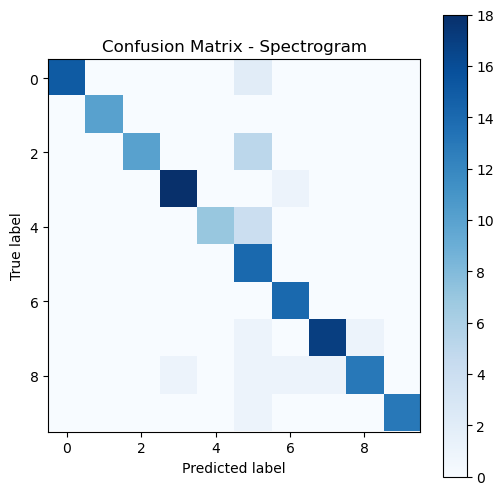

In [48]:
run_experiment(feats_spectrogram, "Spectrogram")

he Spectrogram feature achieved excellent classification performance, with an overall accuracy of 87% and a weighted F1-score of 0.88. Most digits were classified correctly, with digits 1, 3, 6, 7, and 9 showing particularly strong performance. The confusion matrix is dominated by dark diagonal cells, indicating that most predictions are correct. Some confusion remains for digits 4, 5, and 8, but overall the spectrogram provides a very effective representation of the spoken digits for classification.

run Mel spectrogram classification

Feature: Mel Spectrogram
Training examples: 1350
Test examples: 150
Feature size: (1280,)
Training completed in 24.379s
Best parameters: {'C': 100, 'gamma': 0.005}
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        17
           1       0.83      1.00      0.91        10
           2       1.00      0.93      0.97        15
           3       1.00      1.00      1.00        19
           4       1.00      0.91      0.95        11
           5       1.00      0.93      0.96        14
           6       1.00      0.86      0.92        14
           7       0.82      0.95      0.88        19
           8       0.83      0.88      0.86        17
           9       1.00      0.93      0.96        14

    accuracy                           0.94       150
   macro avg       0.95      0.94      0.94       150
weighted avg       0.95      0.94      0.94       150



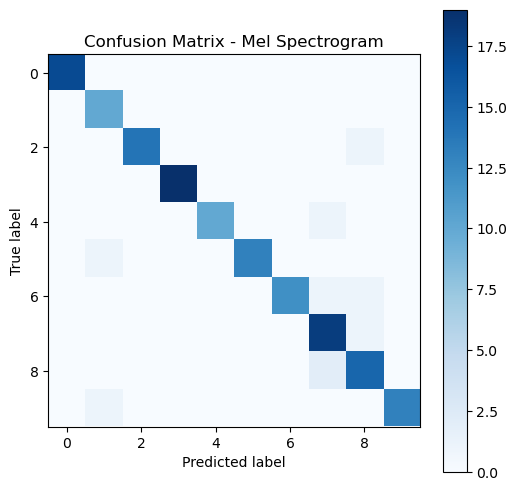

In [49]:
run_experiment(feats_mel, "Mel Spectrogram")


The Mel Spectrogram achieved excellent performance, with an overall accuracy of 94% and a weighted F1-score of 0.94. Most digits were classified correctly, as shown by the strong diagonal pattern in the confusion matrix. Only a few misclassifications occurred, indicating that the Mel Spectrogram is a highly effective feature representation for spoken digit classification and performs better than the standard Spectrogram.

run MFCC classification

Feature: MFCC
Training examples: 1350
Test examples: 150
Feature size: (200,)
Training completed in 13.490s
Best parameters: {'C': 100, 'gamma': 0.005}
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        17
           1       1.00      1.00      1.00        10
           2       1.00      1.00      1.00        15
           3       1.00      1.00      1.00        19
           4       1.00      1.00      1.00        11
           5       1.00      1.00      1.00        14
           6       1.00      1.00      1.00        14
           7       1.00      0.95      0.97        19
           8       1.00      1.00      1.00        17
           9       0.93      1.00      0.97        14

    accuracy                           0.99       150
   macro avg       0.99      0.99      0.99       150
weighted avg       0.99      0.99      0.99       150



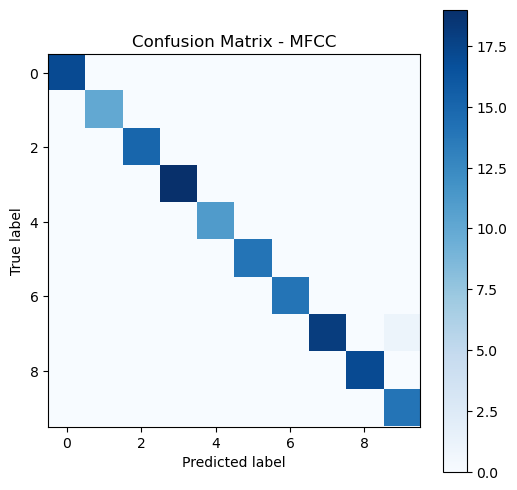

In [50]:
run_experiment(feats_mfcc, "MFCC")

The MFCC feature achieved the best performance, with an overall accuracy of 99% and a weighted F1-score of 0.99. The confusion matrix shows almost perfect classification, with only a very small number of misclassifications. This indicates that MFCC captures the most relevant speech characteristics and is the most effective feature among the three methods for spoken digit classification.